In [1]:
import numpy as np
import pandas as pd

df = pd.read_parquet("data/gdsc2_clean.parquet")
splits = np.load("data/splits.npz", allow_pickle=True)

print(df.shape)
print(sorted(splits.files))

(242036, 17)
['cell_blind_te', 'cell_blind_tr', 'drug_blind_te', 'drug_blind_tr', 'random_te', 'random_tr']


In [2]:
print(list(df.columns))
print()

for name in ["random", "cell_blind", "drug_blind"]:
    tr, te = splits[f"{name}_tr"], splits[f"{name}_te"]
    overlap = len(np.intersect1d(tr, te))
    print(f"{name:12s} train={len(tr):>7,}  test={len(te):>6,}  index overlap={overlap}")

['DATASET', 'NLME_RESULT_ID', 'NLME_CURVE_ID', 'CELL_LINE_NAME', 'SANGER_MODEL_ID', 'CANCER_TYPE', 'DRUG_ID', 'DRUG_NAME', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'MIN_CONC', 'MAX_CONC', 'LN_IC50', 'AUC', 'RMSE', 'Z_SCORE', 'tissue']

random       train=193,628  test=48,408  index overlap=0
cell_blind   train=193,128  test=48,908  index overlap=0
drug_blind   train=191,097  test=50,939  index overlap=0


In [3]:
CELL, DRUG, Y = "SANGER_MODEL_ID", "DRUG_ID", "AUC"

def entity_leak(name, col):
    tr = df.iloc[splits[f"{name}_tr"]][col].unique()
    te = df.iloc[splits[f"{name}_te"]][col].unique()
    shared = np.intersect1d(tr, te)
    print(f"{name:12s} {col:16s} train={len(tr):>4}  test={len(te):>4}  shared={len(shared)}")

entity_leak("random",     CELL)
entity_leak("random",     DRUG)
entity_leak("cell_blind", CELL)
entity_leak("drug_blind", DRUG)

random       SANGER_MODEL_ID  train= 969  test= 969  shared=969
random       DRUG_ID          train= 295  test= 295  shared=295
cell_blind   SANGER_MODEL_ID  train= 775  test= 194  shared=0
drug_blind   DRUG_ID          train= 236  test=  59  shared=0


In [4]:
print(df.index.equals(pd.RangeIndex(len(df))))

True


In [5]:
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

def drug_mean_baseline(tr_idx, te_idx):
    tr, te = df.iloc[tr_idx], df.iloc[te_idx]
    means = tr.groupby(DRUG)[Y].mean()
    global_mean = tr[Y].mean()
    pred = te[DRUG].map(means).fillna(global_mean).to_numpy()
    return rmse(te[Y].to_numpy(), pred)

for name, expected in [("random", 0.0959), ("cell_blind", 0.0965), ("drug_blind", 0.1370)]:
    got = drug_mean_baseline(splits[f"{name}_tr"], splits[f"{name}_te"])
    flag = "ok" if abs(got - expected) < 5e-4 else "MISMATCH"
    print(f"{name:12s} rmse={got:.4f}  expected={expected:.4f}  {flag}")

random       rmse=0.0959  expected=0.0959  ok
cell_blind   rmse=0.0965  expected=0.0965  ok
drug_blind   rmse=0.1370  expected=0.1370  ok


In [6]:
cells = np.sort(df[CELL].unique())
drugs = np.sort(df[DRUG].unique())

cell_ix = {c: i for i, c in enumerate(cells)}
drug_ix = {d: i for i, d in enumerate(drugs)}

df["cell_i"] = df[CELL].map(cell_ix).astype(np.int32)
df["drug_i"] = df[DRUG].map(drug_ix).astype(np.int32)

n_cells, n_drugs = len(cells), len(drugs)
print(f"{n_cells} cells x {n_drugs} drugs = {n_cells * n_drugs:,} possible pairs")
print(f"observed: {len(df):,}  ({len(df) / (n_cells * n_drugs):.1%} dense)")

969 cells x 295 drugs = 285,855 possible pairs
observed: 242,036  (84.7% dense)


In [7]:
import torch
import torch.nn as nn

class MF(nn.Module):
    def __init__(self, n_cells, n_drugs, k=16):
        super().__init__()
        self.P = nn.Embedding(n_cells, k)
        self.Q = nn.Embedding(n_drugs, k)
        self.bc = nn.Embedding(n_cells, 1)
        self.bd = nn.Embedding(n_drugs, 1)
        for e in (self.P, self.Q):
            nn.init.normal_(e.weight, 0, 0.01)
        for e in (self.bc, self.bd):
            nn.init.zeros_(e.weight)

    def forward(self, c, d, seen_c=None, seen_d=None):
        p, q = self.P(c), self.Q(d)
        bc, bd = self.bc(c).squeeze(1), self.bd(d).squeeze(1)
        if seen_c is not None:
            p = p * seen_c[:, None]
            bc = bc * seen_c
        if seen_d is not None:
            q = q * seen_d[:, None]
            bd = bd * seen_d
        return bc + bd + (p * q).sum(1)


def evaluate(m, mu, te_idx, tr_idx):
    seen_cells = set(df.cell_i.values[tr_idx])
    seen_drugs = set(df.drug_i.values[tr_idx])

    c = torch.tensor(df.cell_i.values[te_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[te_idx], dtype=torch.long)
    y = df.AUC.values[te_idx]

    sc = torch.tensor([float(i in seen_cells) for i in df.cell_i.values[te_idx]])
    sd = torch.tensor([float(i in seen_drugs) for i in df.drug_i.values[te_idx]])

    with torch.no_grad():
        pred = (m(c, d, sc, sd) + mu).numpy()

    return float(np.sqrt(((pred - y) ** 2).mean()))

In [8]:
def fit(tr_idx, k=16, wd=1e-5, epochs=400, lr=0.05, seed=0):
    torch.manual_seed(seed)
    c = torch.tensor(df.cell_i.values[tr_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[tr_idx], dtype=torch.long)
    y = torch.tensor(df.AUC.values[tr_idx], dtype=torch.float32)
    mu = y.mean().item()

    m = MF(n_cells, n_drugs, k)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=wd)

    for ep in range(epochs):
        opt.zero_grad()
        loss = ((m(c, d) + mu - y) ** 2).mean()
        loss.backward()
        opt.step()
        if ep % 100 == 0:
            print(f"  ep {ep:4d}  train mse {loss.item():.5f}")
    return m, mu

In [15]:
m, mu = fit(splits['random_tr'])

  ep    0  train mse 0.02159
  ep  100  train mse 0.00243
  ep  200  train mse 0.00243
  ep  300  train mse 0.00243


In [16]:
def evaluate(m, mu, te_idx, tr_idx):
    seen_cells = set(df.cell_i.values[tr_idx])
    seen_drugs = set(df.drug_i.values[tr_idx])

    c = torch.tensor(df.cell_i.values[te_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[te_idx], dtype=torch.long)
    y = df[Y].values[te_idx]

    sc = torch.tensor([float(i in seen_cells) for i in df.cell_i.values[te_idx]])
    sd = torch.tensor([float(i in seen_drugs) for i in df.drug_i.values[te_idx]])

    with torch.no_grad():
        pred = (m(c, d, sc, sd) + mu).numpy()

    return float(np.sqrt(((pred - y) ** 2).mean()))

In [17]:
print(evaluate(m, mu, splits['random_te'], splits['random_tr']))

0.062010872536022915


In [18]:
for name in ['random', 'cell_blind', 'drug_blind']:
    print(name)
    m_i, mu_i = fit(splits[name + '_tr'])
    r = evaluate(m_i, mu_i, splits[name + '_te'], splits[name + '_tr'])
    print(f"  test rmse {r:.4f}\n")

random
  ep    0  train mse 0.02159
  ep  100  train mse 0.00243
  ep  200  train mse 0.00243
  ep  300  train mse 0.00243
  test rmse 0.0620

cell_blind
  ep    0  train mse 0.02159
  ep  100  train mse 0.00253
  ep  200  train mse 0.00253
  ep  300  train mse 0.00253
  test rmse 0.0965

drug_blind
  ep    0  train mse 0.02237
  ep  100  train mse 0.00239
  ep  200  train mse 0.00238
  ep  300  train mse 0.00238
  test rmse 0.1334



In [19]:
import os
os.makedirs('models', exist_ok=True)

models = {}
for name in ['random', 'cell_blind', 'drug_blind']:
    print(name)
    m_i, mu_i = fit(splits[name + '_tr'])
    r = evaluate(m_i, mu_i, splits[name + '_te'], splits[name + '_tr'])
    print(f"  test rmse {r:.4f}")

    torch.save({
        'state_dict': m_i.state_dict(),
        'mu': mu_i,
        'k': 16,
        'n_cells': n_cells,
        'n_drugs': n_drugs,
        'test_rmse': r,
        'cell_ix': cell_ix,
        'drug_ix': drug_ix,
    }, f'models/mf_{name}.pt')

    models[name] = (m_i, mu_i)

print('\nsaved:', os.listdir('models'))

random
  ep    0  train mse 0.02159
  ep  100  train mse 0.00243
  ep  200  train mse 0.00243
  ep  300  train mse 0.00243
  test rmse 0.0620
cell_blind
  ep    0  train mse 0.02159
  ep  100  train mse 0.00253
  ep  200  train mse 0.00253
  ep  300  train mse 0.00253
  test rmse 0.0965
drug_blind
  ep    0  train mse 0.02237
  ep  100  train mse 0.00239
  ep  200  train mse 0.00238
  ep  300  train mse 0.00238
  test rmse 0.1334

saved: ['mf_random.pt', 'mf_cell_blind.pt', 'mf_drug_blind.pt']


In [1]:
from scipy.stats import pearsonr

def per_drug_r(m, mu, te_idx, tr_idx):
    seen_cells = set(df.cell_i.values[tr_idx])
    seen_drugs = set(df.drug_i.values[tr_idx])

    c = torch.tensor(df.cell_i.values[te_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[te_idx], dtype=torch.long)
    sc = torch.tensor([float(i in seen_cells) for i in df.cell_i.values[te_idx]])
    sd = torch.tensor([float(i in seen_drugs) for i in df.drug_i.values[te_idx]])

    with torch.no_grad():
        pred = (m(c, d, sc, sd) + mu).numpy()

    t = pd.DataFrame({
        'drug': df.drug_i.values[te_idx],
        'y': df[Y].values[te_idx],
        'p': pred,
    })

    rs = []
    for drug, g in t.groupby('drug'):
        if len(g) >= 10 and g.y.nunique() > 1 and g.p.nunique() > 1:
            rs.append(pearsonr(g.y, g.p)[0])
    return np.array(rs)

In [21]:
m_i, mu_i = models['drug_blind']
te = splits['drug_blind_te']
c = torch.tensor(df.cell_i.values[te], dtype=torch.long)
d = torch.tensor(df.drug_i.values[te], dtype=torch.long)
sc = torch.ones(len(te))
sd = torch.zeros(len(te))
with torch.no_grad():
    pred = (m_i(c, d, sc, sd) + mu_i).numpy()

t = pd.DataFrame({'cell': df.cell_i.values[te], 'drug': df.drug_i.values[te], 'p': pred})
w = t.pivot_table(index='cell', columns='drug', values='p')
print(w.corr().values[np.triu_indices(w.shape[1], 1)].mean())

1.0


In [22]:
rng = np.random.default_rng(0)
tr_full = splits['random_tr']
perm = rng.permutation(len(tr_full))
n_val = int(0.15 * len(tr_full))
val_idx = tr_full[perm[:n_val]]
sub_tr_idx = tr_full[perm[n_val:]]
print(len(sub_tr_idx), len(val_idx), len(np.intersect1d(sub_tr_idx, val_idx)))

164584 29044 0


In [23]:
rows = []
for k in [4, 8, 16, 32, 64]:
    for wd in [1e-6, 1e-5, 1e-4]:
        m_s, mu_s = fit(sub_tr_idx, k=k, wd=wd, epochs=300)
        r = evaluate(m_s, mu_s, val_idx, sub_tr_idx)
        rows.append({'k': k, 'wd': wd, 'val_rmse': r})
        print(f"k={k:3d}  wd={wd:.0e}  val rmse {r:.4f}")

res = pd.DataFrame(rows).sort_values('val_rmse')
print()
print(res.head(5).to_string(index=False))

  ep    0  train mse 0.02171
  ep  100  train mse 0.00431
  ep  200  train mse 0.00431
k=  4  wd=1e-06  val rmse 0.0706
  ep    0  train mse 0.02171
  ep  100  train mse 0.00435
  ep  200  train mse 0.00435
k=  4  wd=1e-05  val rmse 0.0706
  ep    0  train mse 0.02171
  ep  100  train mse 0.00665
  ep  200  train mse 0.00665
k=  4  wd=1e-04  val rmse 0.0831
  ep    0  train mse 0.02171
  ep  100  train mse 0.00332
  ep  200  train mse 0.00331
k=  8  wd=1e-06  val rmse 0.0669
  ep    0  train mse 0.02171
  ep  100  train mse 0.00340
  ep  200  train mse 0.00336
k=  8  wd=1e-05  val rmse 0.0661
  ep    0  train mse 0.02171
  ep  100  train mse 0.00665
  ep  200  train mse 0.00665
k=  8  wd=1e-04  val rmse 0.0831
  ep    0  train mse 0.02171
  ep  100  train mse 0.00217
  ep  200  train mse 0.00216
k= 16  wd=1e-06  val rmse 0.0691
  ep    0  train mse 0.02171
  ep  100  train mse 0.00233
  ep  200  train mse 0.00233
k= 16  wd=1e-05  val rmse 0.0628
  ep    0  train mse 0.02171
  ep  100  

In [24]:
rows2 = []
for k in [96, 128, 192]:
    for wd in [1e-5, 1e-4]:
        m_s, mu_s = fit(sub_tr_idx, k=k, wd=wd, epochs=300)
        r = evaluate(m_s, mu_s, val_idx, sub_tr_idx)
        rows2.append({'k': k, 'wd': wd, 'val_rmse': r})
        print(f"k={k:3d}  wd={wd:.0e}  val rmse {r:.4f}")

print()
print(pd.DataFrame(rows2).sort_values('val_rmse').to_string(index=False))

  ep    0  train mse 0.02171
  ep  100  train mse 0.00077
  ep  200  train mse 0.00076
k= 96  wd=1e-05  val rmse 0.0583
  ep    0  train mse 0.02171
  ep  100  train mse 0.00665
  ep  200  train mse 0.00665
k= 96  wd=1e-04  val rmse 0.0831
  ep    0  train mse 0.02171
  ep  100  train mse 0.00075
  ep  200  train mse 0.00074
k=128  wd=1e-05  val rmse 0.0584
  ep    0  train mse 0.02171
  ep  100  train mse 0.00665
  ep  200  train mse 0.00665
k=128  wd=1e-04  val rmse 0.0831
  ep    0  train mse 0.02172
  ep  100  train mse 0.00074
  ep  200  train mse 0.00074
k=192  wd=1e-05  val rmse 0.0584
  ep    0  train mse 0.02172
  ep  100  train mse 0.00665
  ep  200  train mse 0.00665
k=192  wd=1e-04  val rmse 0.0831

  k      wd  val_rmse
 96 0.00001  0.058347
128 0.00001  0.058364
192 0.00001  0.058365
192 0.00010  0.083106
 96 0.00010  0.083106
128 0.00010  0.083106


In [25]:
for wd in [1e-5, 1e-4]:
    m_s, mu_s = fit(sub_tr_idx, k=96, wd=wd, epochs=300)
    print(f"wd={wd:.0e}  |P| {m_s.P.weight.abs().mean():.5f}  |Q| {m_s.Q.weight.abs().mean():.5f}")

  ep    0  train mse 0.02171
  ep  100  train mse 0.00077
  ep  200  train mse 0.00076
wd=1e-05  |P| 0.03601  |Q| 0.05752
  ep    0  train mse 0.02171
  ep  100  train mse 0.00665
  ep  200  train mse 0.00665
wd=1e-04  |P| 0.00484  |Q| 0.00814


In [26]:
m_best, mu_best = fit(splits['random_tr'], k=64, wd=1e-5, epochs=300)
r = evaluate(m_best, mu_best, splits['random_te'], splits['random_tr'])
rs = per_drug_r(m_best, mu_best, splits['random_te'], splits['random_tr'])
print(f"test rmse {r:.4f}   per-drug r {rs.mean():.3f}")
torch.save({'state_dict': m_best.state_dict(), 'mu': mu_best, 'k': 64,
            'n_cells': n_cells, 'n_drugs': n_drugs, 'test_rmse': r,
            'cell_ix': cell_ix, 'drug_ix': drug_ix}, 'models/mf_random_tuned.pt')

  ep    0  train mse 0.02159
  ep  100  train mse 0.00101
  ep  200  train mse 0.00100
test rmse 0.0568   per-drug r 0.660


In [27]:
for col in ['PATHWAY_NAME', 'PUTATIVE_TARGET']:
    s = df.groupby('DRUG_ID')[col].first()
    print(f"\n{col}: {s.nunique()} distinct across {len(s)} drugs")
    print(s.value_counts().head(10).to_string())
    print(f"singletons: {(s.value_counts() == 1).sum()}")


PATHWAY_NAME: 24 distinct across 295 drugs
PATHWAY_NAME
Unclassified                     35
Other                            29
PI3K/MTOR signaling              27
Other, kinases                   22
DNA replication                  21
ERK MAPK signaling               15
Apoptosis regulation             13
Genome integrity                 13
Cell cycle                       13
Chromatin histone methylation    13
singletons: 1

PUTATIVE_TARGET: 185 distinct across 295 drugs
PUTATIVE_TARGET
TOP1                      5
MEK1, MEK2                5
PARP1, PARP2              5
EGFR                      4
HSP90                     4
TNKS1, TNKS2              4
AKT1, AKT2, AKT3          4
Antimetabolite            3
Microtubule stabiliser    3
BRAF                      3
singletons: 142


In [28]:
tgt = df.groupby('DRUG_ID').PUTATIVE_TARGET.first().dropna()
genes = tgt.str.split(',').explode().str.strip()
vc = genes.value_counts()
print(f"{len(vc)} distinct genes, {(vc == 1).sum()} appearing in only one drug")
print(f"genes in >=3 drugs: {(vc >= 3).sum()}")
print(vc.head(15).to_string())

237 distinct genes, 141 appearing in only one drug
genes in >=3 drugs: 52
PUTATIVE_TARGET
EGFR      8
AKT1      8
BRD4      7
BCL2      6
BCL-XL    6
AKT2      6
MCL1      6
AKT3      6
ERK2      6
TOP1      5
MEK1      5
MEK2      5
PARP1     5
PARP2     5
PDGFR     5


In [29]:
MIN_DRUGS = 3
keep_genes = sorted(vc[vc >= MIN_DRUGS].index)

dmeta = df.groupby('DRUG_ID').agg(
    pathway=('PATHWAY_NAME', 'first'),
    target=('PUTATIVE_TARGET', 'first'),
).reindex(drugs)

path_oh = pd.get_dummies(dmeta.pathway, prefix='pw', dummy_na=True).astype(float)

tgt_mh = pd.DataFrame(0.0, index=dmeta.index, columns=[f'tg_{g}' for g in keep_genes])
for did, s in dmeta.target.dropna().items():
    for g in [x.strip() for x in s.split(',')]:
        if g in keep_genes:
            tgt_mh.loc[did, f'tg_{g}'] = 1.0

DRUG_FEAT = np.hstack([path_oh.values, tgt_mh.values]).astype('float32')
print(DRUG_FEAT.shape, '| rows aligned:', (dmeta.index.values == drugs).all())
print('drugs with no target feature:', int((tgt_mh.values.sum(1) == 0).sum()))

(295, 77) | rows aligned: True
drugs with no target feature: 158


In [30]:
for t in [2, 3, 5]:
    keep = set(vc[vc >= t].index)
    covered = sum(
        any(g.strip() in keep for g in s.split(','))
        for s in dmeta.target.dropna()
    )
    print(f"min_drugs={t}: {len(keep):3d} genes, {covered}/295 drugs covered")

min_drugs=2:  96 genes, 181/295 drugs covered
min_drugs=3:  52 genes, 137/295 drugs covered
min_drugs=5:  19 genes, 69/295 drugs covered


In [31]:
MIN_DRUGS = 2
keep_genes = sorted(vc[vc >= MIN_DRUGS].index)

tgt_mh = pd.DataFrame(0.0, index=dmeta.index, columns=[f'tg_{g}' for g in keep_genes])
for did, s in dmeta.target.dropna().items():
    for g in [x.strip() for x in s.split(',')]:
        if g in keep_genes:
            tgt_mh.loc[did, f'tg_{g}'] = 1.0

DRUG_FEAT = np.hstack([path_oh.values, tgt_mh.values]).astype('float32')
print(DRUG_FEAT.shape, '| aligned:', (dmeta.index.values == drugs).all())
print('no target feature:', int((tgt_mh.values.sum(1) == 0).sum()))

(295, 121) | aligned: True
no target feature: 114


In [10]:
class HybridMF(nn.Module):
    def __init__(self, n_cells, n_drugs, drug_feat, k=64):
        super().__init__()
        self.register_buffer('DF', torch.tensor(drug_feat))

        self.P = nn.Embedding(n_cells, k)
        self.bc = nn.Embedding(n_cells, 1)

        self.Qf = nn.Linear(drug_feat.shape[1], k)   # features -> drug vector
        self.bdf = nn.Linear(drug_feat.shape[1], 1)  # features -> drug bias

        nn.init.normal_(self.P.weight, 0, 0.01)
        nn.init.zeros_(self.bc.weight)

    def forward(self, c, d, seen_c=None, seen_d=None):
        p = self.P(c)
        f = self.DF[d]                      # (batch, n_feat)
        q = self.Qf(f)                      # (batch, k)
        bc = self.bc(c).squeeze(1)
        bd = self.bdf(f).squeeze(1)

        if seen_c is not None:
            p = p * seen_c[:, None]
            bc = bc * seen_c
        # no seen_d masking — features exist for unseen drugs, that's the point

        return bc + bd + (p * q).sum(1)

In [11]:
def fit2(model_cls, tr_idx, k=64, wd=1e-5, epochs=300, lr=0.05, seed=0, **kw):
    torch.manual_seed(seed)
    c = torch.tensor(df.cell_i.values[tr_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[tr_idx], dtype=torch.long)
    y = torch.tensor(df[Y].values[tr_idx], dtype=torch.float32)
    mu = y.mean().item()

    m = model_cls(n_cells, n_drugs, k=k, **kw)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        opt.zero_grad()
        loss = ((m(c, d) + mu - y) ** 2).mean()
        loss.backward()
        opt.step()
        if ep % 100 == 0:
            print(f"  ep {ep:4d}  train mse {loss.item():.5f}")
    return m, mu

In [34]:
m_h, mu_h = fit2(HybridMF, splits['drug_blind_tr'], drug_feat=DRUG_FEAT)
r = evaluate(m_h, mu_h, splits['drug_blind_te'], splits['drug_blind_tr'])
rs = per_drug_r(m_h, mu_h, splits['drug_blind_te'], splits['drug_blind_tr'])
print(f"\nhybrid drug-blind: rmse {r:.4f}  per-drug r {rs.mean():.3f}  ({len(rs)} drugs)")

  ep    0  train mse 0.03646
  ep  100  train mse 0.00942
  ep  200  train mse 0.00870

hybrid drug-blind: rmse 0.2961  per-drug r 0.431  (59 drugs)


In [35]:
with torch.no_grad():
    c = torch.tensor(df.cell_i.values[splits['drug_blind_te']], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[splits['drug_blind_te']], dtype=torch.long)
    sc = torch.ones(len(c))
    pred = (m_h(c, d, sc, None) + mu_h).numpy()
y_true = df[Y].values[splits['drug_blind_te']]
print(f"pred  min {pred.min():.3f}  max {pred.max():.3f}  mean {pred.mean():.3f}  sd {pred.std():.3f}")
print(f"true  min {y_true.min():.3f}  max {y_true.max():.3f}  mean {y_true.mean():.3f}  sd {y_true.std():.3f}")
print(f"|Qf.weight| {m_h.Qf.weight.abs().mean():.4f}   |P| {m_h.P.weight.abs().mean():.4f}")

pred  min -1.993  max 1.658  mean 0.852  sd 0.298
true  min 0.010  max 0.998  mean 0.878  sd 0.137
|Qf.weight| 0.0818   |P| 0.0327


In [12]:
def fit3(model_cls, tr_idx, k=64, wd=1e-5, wd_feat=1e-2, epochs=400, lr=0.02, seed=0, **kw):
    torch.manual_seed(seed)
    c = torch.tensor(df.cell_i.values[tr_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[tr_idx], dtype=torch.long)
    y = torch.tensor(df[Y].values[tr_idx], dtype=torch.float32)
    mu = y.mean().item()

    m = model_cls(n_cells, n_drugs, k=k, **kw)
    feat_params = list(m.Qf.parameters()) + list(m.bdf.parameters())
    feat_ids = {id(p) for p in feat_params}
    other = [p for p in m.parameters() if id(p) not in feat_ids]

    opt = torch.optim.Adam([
        {'params': other,       'weight_decay': wd},
        {'params': feat_params, 'weight_decay': wd_feat},
    ], lr=lr)

    for ep in range(epochs):
        opt.zero_grad()
        loss = ((m(c, d) + mu - y) ** 2).mean()
        loss.backward()
        opt.step()
        if ep % 100 == 0:
            print(f"  ep {ep:4d}  train mse {loss.item():.5f}")
    return m, mu

In [37]:
m_h2, mu_h2 = fit3(HybridMF, splits['drug_blind_tr'], drug_feat=DRUG_FEAT)
r = evaluate(m_h2, mu_h2, splits['drug_blind_te'], splits['drug_blind_tr'])
rs = per_drug_r(m_h2, mu_h2, splits['drug_blind_te'], splits['drug_blind_tr'])
print(f"\nhybrid v2 drug-blind: rmse {r:.4f}  per-drug r {rs.mean():.3f}")

  ep    0  train mse 0.03646
  ep  100  train mse 0.01521
  ep  200  train mse 0.01522
  ep  300  train mse 0.01522

hybrid v2 drug-blind: rmse 0.1260  per-drug r 0.339


In [38]:
rng = np.random.default_rng(0)
tr_full = splits['drug_blind_tr']
tr_drugs = np.unique(df.drug_i.values[tr_full])
vd = set(rng.choice(tr_drugs, size=int(0.2 * len(tr_drugs)), replace=False))
mask = np.isin(df.drug_i.values[tr_full], list(vd))
db_val, db_tr = tr_full[mask], tr_full[~mask]
print(len(db_tr), len(db_val), 'drug overlap:',
      len(set(df.drug_i.values[db_tr]) & set(df.drug_i.values[db_val])))

for wdf in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    m_s, mu_s = fit3(HybridMF, db_tr, wd_feat=wdf, drug_feat=DRUG_FEAT)
    r = evaluate(m_s, mu_s, db_val, db_tr)
    rs = per_drug_r(m_s, mu_s, db_val, db_tr)
    print(f"wd_feat={wdf:.0e}  val rmse {r:.4f}  r {rs.mean():.3f}")

153610 37487 drug overlap: 0
  ep    0  train mse 0.03713
  ep  100  train mse 0.00763
  ep  200  train mse 0.00759
  ep  300  train mse 0.00759
wd_feat=1e-04  val rmse 0.2809  r 0.467
  ep    0  train mse 0.03713
  ep  100  train mse 0.00841
  ep  200  train mse 0.00837
  ep  300  train mse 0.00837
wd_feat=3e-04  val rmse 0.2621  r 0.471
  ep    0  train mse 0.03713
  ep  100  train mse 0.00956
  ep  200  train mse 0.00958
  ep  300  train mse 0.00958
wd_feat=1e-03  val rmse 0.2218  r 0.465
  ep    0  train mse 0.03713
  ep  100  train mse 0.01133
  ep  200  train mse 0.01132
  ep  300  train mse 0.01132
wd_feat=3e-03  val rmse 0.1773  r 0.444
  ep    0  train mse 0.03713
  ep  100  train mse 0.01417
  ep  200  train mse 0.01417
  ep  300  train mse 0.01417
wd_feat=1e-02  val rmse 0.1443  r 0.411


In [39]:
import os, json
os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)

np.save('data/drug_feat.npy', DRUG_FEAT)
np.save('data/db_tr.npy', db_tr)
np.save('data/db_val.npy', db_val)

torch.save({'state_dict': m_h2.state_dict(), 'mu': mu_h2, 'k': 64,
            'wd_feat': 1e-2, 'n_cells': n_cells, 'n_drugs': n_drugs,
            'drug_feat': DRUG_FEAT, 'cell_ix': cell_ix, 'drug_ix': drug_ix,
            'test_rmse': 0.1260, 'per_drug_r': 0.339},
           'models/hybrid_drug_blind.pt')

json.dump({
    'mf_tuned': {'k': 64, 'wd': 1e-5, 'random_rmse': 0.0568, 'random_r': 0.660},
    'mf_untuned': {'random': 0.0620, 'cell_blind': 0.0965, 'drug_blind': 0.1334},
    'baseline': {'random': 0.0899, 'cell_blind': 0.0965, 'drug_blind': 0.1334},
    'hybrid_drug_blind': {'wd_feat': 1e-2, 'rmse': 0.1260, 'r': 0.339},
    'wd_feat_sweep': {'1e-4': [0.2809, 0.467], '3e-4': [0.2621, 0.471],
                      '1e-3': [0.2218, 0.465], '3e-3': [0.1773, 0.444],
                      '1e-2': [0.1443, 0.411]},
    'next': 'extend wd_feat sweep to 3e-2, 1e-1; then cell-side features'
}, open('results.json', 'w'), indent=2)

print(sorted(os.listdir('models')), sorted(os.listdir('data')))

['hybrid_drug_blind.pt', 'mf_cell_blind.pt', 'mf_drug_blind.pt', 'mf_random.pt', 'mf_random_tuned.pt'] ['GDSC2_fitted_dose_response_27Oct23.xlsx', 'db_tr.npy', 'db_val.npy', 'drug_feat.npy', 'gdsc2_clean.parquet', 'model_list_20260619.csv', 'splits.npz']


In [13]:
import os, json
import numpy as np, torch

DRUG_FEAT = np.load('data/drug_feat.npy')
db_tr = np.load('data/db_tr.npy')
db_val = np.load('data/db_val.npy')
splits = np.load('data/splits.npz' if os.path.exists('data/splits.npz') else 'splits.npz')

ck = torch.load('models/hybrid_drug_blind.pt', weights_only=False)
assert ck['n_cells'] == n_cells and ck['n_drugs'] == n_drugs, "encoding mismatch, rebuild cell_i/drug_i"
m_h2 = HybridMF(ck['n_cells'], ck['n_drugs'], ck['drug_feat'], k=ck['k'])
m_h2.load_state_dict(ck['state_dict']); m_h2.eval()
mu_h2 = ck['mu']

r = evaluate(m_h2, mu_h2, splits['drug_blind_te'], splits['drug_blind_tr'])
rs = per_drug_r(m_h2, mu_h2, splits['drug_blind_te'], splits['drug_blind_tr'])
print(f"rmse {r:.4f} (expect 0.1260) | per-drug r {rs.mean():.3f} (expect 0.339)")
print(json.load(open('results.json'))['next'])

rmse 0.1260 (expect 0.1260) | per-drug r 0.339 (expect 0.339)
extend wd_feat sweep to 3e-2, 1e-1; then cell-side features


In [14]:
sweep = {}
for wf in [1e-2, 3e-2, 1e-1, 3e-1]:
    print(f"\nwd_feat = {wf:g}")
    m_s, mu_s = fit3(HybridMF, db_tr, wd_feat=wf, drug_feat=DRUG_FEAT)
    rm = evaluate(m_s, mu_s, db_val, db_tr)
    rr = per_drug_r(m_s, mu_s, db_val, db_tr).mean()
    sweep[wf] = (rm, rr)
    print(f"  VAL rmse {rm:.4f}  per-drug r {rr:.3f}")

print("\nwd_feat   val_rmse   val_r")
for wf, (rm, rr) in sweep.items():
    print(f"{wf:<8g}  {rm:.4f}     {rr:.3f}")


wd_feat = 0.01
  ep    0  train mse 0.03713
  ep  100  train mse 0.01417
  ep  200  train mse 0.01417
  ep  300  train mse 0.01417
  VAL rmse 0.1443  per-drug r 0.411

wd_feat = 0.03
  ep    0  train mse 0.03713
  ep  100  train mse 0.01710
  ep  200  train mse 0.01711
  ep  300  train mse 0.01711
  VAL rmse 0.1317  per-drug r 0.381

wd_feat = 0.1
  ep    0  train mse 0.03713
  ep  100  train mse 0.01920
  ep  200  train mse 0.01920
  ep  300  train mse 0.01920
  VAL rmse 0.1279  per-drug r 0.380

wd_feat = 0.3
  ep    0  train mse 0.03713
  ep  100  train mse 0.02060
  ep  200  train mse 0.02060
  ep  300  train mse 0.02060
  VAL rmse 0.1286  per-drug r 0.380

wd_feat   val_rmse   val_r
0.01      0.1443     0.411
0.03      0.1317     0.381
0.1       0.1279     0.380
0.3       0.1286     0.380


In [15]:
rm_list, r_list = [], []
for s in [0, 1, 2]:
    print(f"\nseed {s}")
    m_f, mu_f = fit3(HybridMF, splits['drug_blind_tr'], wd_feat=1e-1, seed=s, drug_feat=DRUG_FEAT)
    rm_list.append(evaluate(m_f, mu_f, splits['drug_blind_te'], splits['drug_blind_tr']))
    r_list.append(per_drug_r(m_f, mu_f, splits['drug_blind_te'], splits['drug_blind_tr']).mean())
    if s == 0:
        m_final_drug, mu_final_drug = m_f, mu_f

rm_list, r_list = np.array(rm_list), np.array(r_list)
print(f"\nTEST drug-blind: rmse {rm_list.mean():.4f} ± {rm_list.std():.4f} | per-drug r {r_list.mean():.3f} ± {r_list.std():.3f}")
print("baseline rmse 0.1334")

torch.save({'state_dict': m_final_drug.state_dict(), 'mu': mu_final_drug, 'k': 64, 'wd_feat': 1e-1,
            'n_cells': n_cells, 'n_drugs': n_drugs, 'drug_feat': DRUG_FEAT},
           'models/hybrid_drug_final.pt')

res = json.load(open('results.json'))
res['wd_feat_sweep'].update({f"{k:g}": [round(v[0], 4), round(v[1], 3)] for k, v in sweep.items()})
res['hybrid_drug_final'] = {'wd_feat': 1e-1, 'seeds': 3,
                            'rmse_mean': float(rm_list.mean()), 'rmse_sd': float(rm_list.std()),
                            'r_mean': float(r_list.mean()), 'r_sd': float(r_list.std())}
res['next'] = 'cell-side features (tissue) for cell-blind'
json.dump(res, open('results.json', 'w'), indent=2)
print("saved")


seed 0
  ep    0  train mse 0.03646
  ep  100  train mse 0.01864
  ep  200  train mse 0.01864
  ep  300  train mse 0.01864

seed 1
  ep    0  train mse 0.03025
  ep  100  train mse 0.01864
  ep  200  train mse 0.01864
  ep  300  train mse 0.01864

seed 2
  ep    0  train mse 0.02933
  ep  100  train mse 0.01864
  ep  200  train mse 0.01864
  ep  300  train mse 0.01864

TEST drug-blind: rmse 0.1264 ± 0.0000 | per-drug r 0.310 ± 0.000
baseline rmse 0.1334
saved


In [16]:
# 1. seeds: full precision, and whether different seeds give different starting weights
print("rmse per seed:", rm_list)
print("r per seed:   ", r_list)
for s in [0, 1]:
    torch.manual_seed(s)
    print(f"seed {s} init P[0,:3]:", HybridMF(n_cells, n_drugs, DRUG_FEAT, k=64).P.weight[0, :3].detach().numpy())

# 2. collapse check: do unseen drugs get distinct cell-line rankings?
def interdrug_corr(m, mu, te_idx):
    te_drugs = np.unique(df.drug_i.values[te_idx])
    c = torch.arange(n_cells).repeat(len(te_drugs))
    d = torch.tensor(np.repeat(te_drugs, n_cells), dtype=torch.long)
    with torch.no_grad():
        pred = (m(c, d) + mu).numpy().reshape(len(te_drugs), n_cells)
    C = np.corrcoef(pred)
    return C[np.triu_indices(len(te_drugs), 1)].mean()

print("\ninter-drug corr, wd_feat 0.01:", round(interdrug_corr(m_h2, mu_h2, splits['drug_blind_te']), 3))
print("inter-drug corr, wd_feat 0.1: ", round(interdrug_corr(m_final_drug, mu_final_drug, splits['drug_blind_te']), 3))

rmse per seed: [0.12638367 0.12638367 0.12638367]
r per seed:    [0.31000912 0.31000912 0.31000912]
seed 0 init P[0,:3]: [-0.00311539  0.00033953 -0.02020008]
seed 1 init P[0,:3]: [0.0060149  0.00905157 0.02056925]

inter-drug corr, wd_feat 0.01: 0.96
inter-drug corr, wd_feat 0.1:  1.0


In [17]:
res = json.load(open('results.json'))
res['hybrid_drug_final']['note'] = ('val-selected wd_feat=0.1: interaction term collapses (inter-drug corr 1.0), '
                                    'model = cell bias + feature-predicted drug bias; seed-invariant')
res['interdrug_corr'] = {'wd_feat_0.01': 0.96, 'wd_feat_0.1': 1.0}
json.dump(res, open('results.json', 'w'), indent=2)

print(df.columns.tolist())
print(df.select_dtypes('object').nunique())

['DATASET', 'NLME_RESULT_ID', 'NLME_CURVE_ID', 'CELL_LINE_NAME', 'SANGER_MODEL_ID', 'CANCER_TYPE', 'DRUG_ID', 'DRUG_NAME', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'MIN_CONC', 'MAX_CONC', 'LN_IC50', 'AUC', 'RMSE', 'Z_SCORE', 'tissue', 'cell_i', 'drug_i']
DATASET              1
CELL_LINE_NAME     969
SANGER_MODEL_ID    969
CANCER_TYPE         42
DRUG_NAME          286
PUTATIVE_TARGET    185
PATHWAY_NAME        24
tissue              28
dtype: int64


/var/folders/47/2ds8wd_554q80mwmsxtly8lc0000gn/T/ipykernel_58820/3971810754.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes('object').nunique())


In [19]:
mut_path = 'mutations_summary_20260724.csv'
mut = pd.read_csv(mut_path)
print(mut_path, mut.shape)
print(mut.columns.tolist())
print(mut.head(3).to_string())

# does it join to your cells?
id_col = [c for c in mut.columns if 'model_id' in c.lower()][0]
overlap = set(mut[id_col]) & set(df.SANGER_MODEL_ID)
print(f"\n{len(overlap)} of {df.SANGER_MODEL_ID.nunique()} cell lines have mutation data")

# for the tissue step
print('\nparquet columns:', df.columns.tolist())
print(df.select_dtypes('object').nunique())

mutations_summary_20260724.csv (15025, 20)
['gene_symbol', 'ensembl_gene_id', 'transcript_id', 'model_name', 'model_id', 'protein_mutation', 'rna_mutation', 'cdna_mutation', 'chromosome', 'position', 'reference', 'alternative', 'cancer_driver', 'cancer_predisposition_variant', 'effect', 'vaf', 'coding', 'source', 'gene_id', 'found_in_matched_tumour']
  gene_symbol  ensembl_gene_id transcript_id     model_name   model_id protein_mutation     rna_mutation    cdna_mutation chromosome  position reference alternative cancer_driver cancer_predisposition_variant      effect     vaf coding  source    gene_id found_in_matched_tumour
0       RBM10  ENSG00000182872           NaN  WTSI-COLO_216  SIDM01951          p.Q669*        r.2005c>u        c.2005C>T        NaN       NaN       NaN         NaN             t                             f    nonsense  1.0000      t  Sanger  SIDG26815                       f
1      ARID1A  ENSG00000117713           NaN  WTSI-COLO_021  SIDM01268      p.R306fs*57  

/var/folders/47/2ds8wd_554q80mwmsxtly8lc0000gn/T/ipykernel_58820/1807137629.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes('object').nunique())


In [20]:
# one row per cell line, in cell_i order
cell_info = df.groupby('cell_i')[['SANGER_MODEL_ID', 'tissue']].first().sort_index()
assert (cell_info.index == np.arange(n_cells)).all()
ids = cell_info.SANGER_MODEL_ID

# tissue one-hot
T = pd.get_dummies(cell_info.tissue).astype('float32').values

# driver-gene multi-hot: keep genes mutated in >= 10 cell lines
drv = mut[mut.cancer_driver.astype(str).str.lower().isin(['t', 'true'])]
drv = drv[drv.model_id.isin(ids)]
gene_n = drv.groupby('gene_symbol').model_id.nunique()
keep = gene_n[gene_n >= 10].index
M = (pd.crosstab(drv.model_id, drv.gene_symbol)[keep] > 0).astype('float32')
M = M.reindex(ids).fillna(0).values
has_data = ids.isin(mut.model_id).astype('float32').values[:, None]

CELL_FEAT_T  = np.hstack([T, has_data]).astype('float32')
CELL_FEAT_TM = np.hstack([T, M, has_data]).astype('float32')
print('tissue only:', CELL_FEAT_T.shape, '| tissue + mutations:', CELL_FEAT_TM.shape)
print('top genes:', gene_n.sort_values(ascending=False).head(8).to_dict())

# validation split inside cell-blind train: hold out 15% of training cell lines
rng = np.random.default_rng(0)
cb = splits['cell_blind_tr']
tr_cells = np.unique(df.cell_i.values[cb])
val_cells = rng.choice(tr_cells, size=int(0.15 * len(tr_cells)), replace=False)
is_val = np.isin(df.cell_i.values[cb], val_cells)
cb_tr, cb_val = cb[~is_val], cb[is_val]
print('cb_tr', len(cb_tr), '| cb_val', len(cb_val), '| shared cells',
      len(set(df.cell_i.values[cb_tr]) & set(df.cell_i.values[cb_val])))

np.save('data/cell_feat_t.npy', CELL_FEAT_T); np.save('data/cell_feat_tm.npy', CELL_FEAT_TM)
np.save('data/cb_tr.npy', cb_tr); np.save('data/cb_val.npy', cb_val)

tissue only: (969, 29) | tissue + mutations: (969, 250)
top genes: {'TP53': 645, 'KRAS': 125, 'KMT2C': 125, 'PTEN': 106, 'KMT2D': 104, 'RB1': 97, 'PIK3CA': 94, 'EP300': 87}
cb_tr 164502 | cb_val 28626 | shared cells 0


In [21]:
class HybridCellMF(nn.Module):
    def __init__(self, n_cells, n_drugs, cell_feat, k=64):
        super().__init__()
        self.register_buffer('CF', torch.tensor(cell_feat))
        self.Q = nn.Embedding(n_drugs, k)
        self.bd = nn.Embedding(n_drugs, 1)
        self.Pf = nn.Linear(cell_feat.shape[1], k)    # features -> cell vector
        self.bcf = nn.Linear(cell_feat.shape[1], 1)   # features -> cell bias
        nn.init.normal_(self.Q.weight, 0, 0.01)
        nn.init.zeros_(self.bd.weight)

    def forward(self, c, d, seen_c=None, seen_d=None):
        f = self.CF[c]
        p, bc = self.Pf(f), self.bcf(f).squeeze(1)
        q, bd = self.Q(d), self.bd(d).squeeze(1)
        if seen_d is not None:
            q = q * seen_d[:, None]; bd = bd * seen_d
        # no seen_c masking: unseen cells still have features
        return bc + bd + (p * q).sum(1)


def fit_feat(model_cls, tr_idx, k=64, wd=1e-5, wd_feat=1e-1, epochs=400, lr=0.02, seed=0, **kw):
    torch.manual_seed(seed)
    c = torch.tensor(df.cell_i.values[tr_idx], dtype=torch.long)
    d = torch.tensor(df.drug_i.values[tr_idx], dtype=torch.long)
    y = torch.tensor(df.AUC.values[tr_idx], dtype=torch.float32)
    mu = y.mean().item()
    m = model_cls(n_cells, n_drugs, k=k, **kw)
    feat = [p for n, p in m.named_parameters() if n.split('.')[0] in ('Qf', 'bdf', 'Pf', 'bcf')]
    ids_f = {id(p) for p in feat}
    other = [p for p in m.parameters() if id(p) not in ids_f]
    opt = torch.optim.Adam([{'params': other, 'weight_decay': wd},
                            {'params': feat, 'weight_decay': wd_feat}], lr=lr)
    for ep in range(epochs):
        opt.zero_grad()
        loss = ((m(c, d) + mu - y) ** 2).mean()
        loss.backward(); opt.step()
    return m, mu

In [22]:
m_ref, mu_ref = fit(cb_tr, k=64)
print(f"reference (plain MF, fallback): val rmse {evaluate(m_ref, mu_ref, cb_val, cb_tr):.4f}\n")

cell_sweep = {}
for fname, F in [('tissue', CELL_FEAT_T), ('tissue+mut', CELL_FEAT_TM)]:
    for wf in [1e-3, 1e-2, 1e-1, 1.0]:
        m_s, mu_s = fit_feat(HybridCellMF, cb_tr, wd_feat=wf, cell_feat=F)
        rm = evaluate(m_s, mu_s, cb_val, cb_tr)
        rr = per_drug_r(m_s, mu_s, cb_val, cb_tr).mean()
        cell_sweep[(fname, wf)] = (rm, rr)
        print(f"{fname:<11} wd_feat {wf:<6g} val rmse {rm:.4f}  per-drug r {rr:.3f}")

  ep    0  train mse 0.02163
  ep  100  train mse 0.00096
  ep  200  train mse 0.00095
  ep  300  train mse 0.00095
reference (plain MF, fallback): val rmse 0.0917

tissue      wd_feat 0.001  val rmse 0.0837  per-drug r 0.235
tissue      wd_feat 0.01   val rmse 0.0850  per-drug r 0.170
tissue      wd_feat 0.1    val rmse 0.0881  per-drug r 0.129
tissue      wd_feat 1      val rmse 0.0909  per-drug r 0.133
tissue+mut  wd_feat 0.001  val rmse 0.0870  per-drug r 0.219
tissue+mut  wd_feat 0.01   val rmse 0.0852  per-drug r 0.199
tissue+mut  wd_feat 0.1    val rmse 0.0880  per-drug r 0.139
tissue+mut  wd_feat 1      val rmse 0.0908  per-drug r 0.142


In [23]:
ct = (pd.crosstab(drv.model_id, drv.gene_symbol) > 0).astype('float32').reindex(ids).fillna(0)
keep30 = gene_n[gene_n >= 30].index
CELL_FEAT_TM30 = np.hstack([T, ct[keep30].values, has_data]).astype('float32')
np.save('data/cell_feat_tm30.npy', CELL_FEAT_TM30)
print('tissue + common mutations:', CELL_FEAT_TM30.shape, '\n')

runs = [('tissue',       CELL_FEAT_T,    [1e-5, 1e-4, 3e-4]),
        ('tissue+mut',   CELL_FEAT_TM,   [3e-3, 3e-2]),
        ('tissue+mut30', CELL_FEAT_TM30, [1e-3, 3e-3, 1e-2])]

for fname, F, grid in runs:
    for wf in grid:
        m_s, mu_s = fit_feat(HybridCellMF, cb_tr, wd_feat=wf, cell_feat=F)
        rm = evaluate(m_s, mu_s, cb_val, cb_tr)
        rr = per_drug_r(m_s, mu_s, cb_val, cb_tr).mean()
        cell_sweep[(fname, wf)] = (rm, rr)
        print(f"{fname:<13} wd_feat {wf:<6g} val rmse {rm:.4f}  per-drug r {rr:.3f}")

print('\nbest per feature set (by val rmse):')
for fname in ['tissue', 'tissue+mut', 'tissue+mut30']:
    best = min((v[0], k[1], v[1]) for k, v in cell_sweep.items() if k[0] == fname)
    print(f"  {fname:<13} wd_feat {best[1]:g}  rmse {best[0]:.4f}  r {best[2]:.3f}")

tissue + common mutations: (969, 81) 

tissue        wd_feat 1e-05  val rmse 0.0841  per-drug r 0.272
tissue        wd_feat 0.0001 val rmse 0.0837  per-drug r 0.273
tissue        wd_feat 0.0003 val rmse 0.0835  per-drug r 0.264
tissue+mut    wd_feat 0.003  val rmse 0.0865  per-drug r 0.201
tissue+mut    wd_feat 0.03   val rmse 0.0866  per-drug r 0.168
tissue+mut30  wd_feat 0.001  val rmse 0.0843  per-drug r 0.238
tissue+mut30  wd_feat 0.003  val rmse 0.0846  per-drug r 0.214
tissue+mut30  wd_feat 0.01   val rmse 0.0850  per-drug r 0.181

best per feature set (by val rmse):
  tissue        wd_feat 0.0003  rmse 0.0835  r 0.264
  tissue+mut    wd_feat 0.01  rmse 0.0852  r 0.199
  tissue+mut30  wd_feat 0.001  rmse 0.0843  r 0.238


In [24]:
# give tissue+mut30 the same chance as tissue
for wf in [1e-4, 3e-4]:
    m_s, mu_s = fit_feat(HybridCellMF, cb_tr, wd_feat=wf, cell_feat=CELL_FEAT_TM30)
    cell_sweep[('tissue+mut30', wf)] = (evaluate(m_s, mu_s, cb_val, cb_tr),
                                        per_drug_r(m_s, mu_s, cb_val, cb_tr).mean())
    print(f"tissue+mut30  wd_feat {wf:g}  val rmse {cell_sweep[('tissue+mut30', wf)][0]:.4f}")
wf_m30 = min((v[0], k[1]) for k, v in cell_sweep.items() if k[0] == 'tissue+mut30')[1]
print(f"tissue+mut30 best wd_feat: {wf_m30:g}\n")

# test: 3 seeds each
final_cell = {}
for fname, F, wf in [('tissue', CELL_FEAT_T, 3e-4), ('tissue+mut30', CELL_FEAT_TM30, wf_m30)]:
    rms, rs = [], []
    for s in [0, 1, 2]:
        m_f, mu_f = fit_feat(HybridCellMF, splits['cell_blind_tr'], wd_feat=wf, seed=s, cell_feat=F)
        rms.append(evaluate(m_f, mu_f, splits['cell_blind_te'], splits['cell_blind_tr']))
        rs.append(per_drug_r(m_f, mu_f, splits['cell_blind_te'], splits['cell_blind_tr']).mean())
        if s == 0 and fname == 'tissue':
            torch.save({'state_dict': m_f.state_dict(), 'mu': mu_f, 'k': 64, 'wd_feat': wf,
                        'n_cells': n_cells, 'n_drugs': n_drugs, 'cell_feat': F},
                       'models/hybrid_cell_final.pt')
    rms, rs = np.array(rms), np.array(rs)
    final_cell[fname] = {'wd_feat': wf, 'rmse_mean': float(rms.mean()), 'rmse_sd': float(rms.std()),
                         'r_mean': float(rs.mean()), 'r_sd': float(rs.std())}
    print(f"TEST cell-blind {fname:<13} rmse {rms.mean():.4f} ± {rms.std():.4f} | r {rs.mean():.3f} ± {rs.std():.3f}")
print("baseline rmse 0.0965")

res = json.load(open('results.json'))
res['hybrid_cell_final'] = final_cell
res['cell_sweep'] = {f"{k[0]}|{k[1]:g}": [round(v[0], 4), round(v[1], 3)] for k, v in cell_sweep.items()}
res['next'] = 'seed reruns: baseline + MF random; then results table + figures'
json.dump(res, open('results.json', 'w'), indent=2)
print("saved")

tissue+mut30  wd_feat 0.0001  val rmse 0.0864
tissue+mut30  wd_feat 0.0003  val rmse 0.0851
tissue+mut30 best wd_feat: 0.001

TEST cell-blind tissue        rmse 0.0868 ± 0.0000 | r 0.293 ± 0.000
TEST cell-blind tissue+mut30  rmse 0.0860 ± 0.0000 | r 0.297 ± 0.000
baseline rmse 0.0965
saved


In [25]:
def interaction_check(m, mu, te_idx):
    te_cells = np.unique(df.cell_i.values[te_idx])
    c = torch.tensor(np.tile(te_cells, n_drugs), dtype=torch.long)
    d = torch.arange(n_drugs).repeat_interleave(len(te_cells))
    with torch.no_grad():
        f = m.CF[c]
        inter = (m.Pf(f) * m.Q(d)).sum(1)
        bias = m.bcf(f).squeeze(1)
        pred = (m(c, d) + mu).numpy().reshape(n_drugs, len(te_cells))
    C = np.corrcoef(pred)
    return np.nanmean(C[np.triu_indices(n_drugs, 1)]), inter.abs().mean().item(), bias.std().item()

ck = torch.load('models/hybrid_cell_final.pt', weights_only=False)
m_ct = HybridCellMF(n_cells, n_drugs, ck['cell_feat'], k=64)
m_ct.load_state_dict(ck['state_dict']); m_ct.eval()

for name, m_, mu_ in [('tissue', m_ct, ck['mu']), ('tissue+mut30', m_f, mu_f)]:
    corr, inter, bias = interaction_check(m_, mu_, splits['cell_blind_te'])
    print(f"{name:<13} cross-drug corr {corr:.3f} | mean |interaction| {inter:.5f} | cell-bias sd {bias:.5f}")

tissue        cross-drug corr 0.283 | mean |interaction| 0.02832 | cell-bias sd 0.01963
tissue+mut30  cross-drug corr 0.422 | mean |interaction| 0.02370 | cell-bias sd 0.02148


In [26]:
def baseline_pred(tr, te):
    d = df.iloc[tr]; mu = d.AUC.mean()
    bd = d.groupby('drug_i').AUC.mean() - mu
    bc = (d.AUC - mu - d.drug_i.map(bd)).groupby(d.cell_i).mean()
    t = df.iloc[te]
    return mu + t.drug_i.map(bd).fillna(0).values + t.cell_i.map(bc).fillna(0).values

def r_from_pred(pred, te):
    t = pd.DataFrame({'d': df.drug_i.values[te], 'y': df.AUC.values[te], 'p': pred})
    rs = [g.y.corr(g.p) for _, g in t.groupby('d') if g.p.nunique() > 1 and len(g) > 2]
    return np.mean(rs) if rs else np.nan

names = ['random', 'cell_blind', 'drug_blind']

# baseline (deterministic, no seeds needed)
base = {}
for s in names:
    tr, te = splits[s + '_tr'], splits[s + '_te']
    p = baseline_pred(tr, te)
    base[s] = {'rmse_mean': float(np.sqrt(((p - df.AUC.values[te]) ** 2).mean())), 'rmse_sd': 0.0,
               'r_mean': float(r_from_pred(p, te)), 'r_sd': 0.0}
print('baseline random rmse', round(base['random']['rmse_mean'], 4), '(expect 0.0899)')

# tuned MF, 3 seeds per split
mf = {}
for s in names:
    rms, rs = [], []
    for seed in [0, 1, 2]:
        m_, mu_ = fit(splits[s + '_tr'], k=64, wd=1e-5, seed=seed)
        rms.append(evaluate(m_, mu_, splits[s + '_te'], splits[s + '_tr']))
        rr = per_drug_r(m_, mu_, splits[s + '_te'], splits[s + '_tr'])
        rs.append(rr.mean() if len(rr) else np.nan)
    mf[s] = {'rmse_mean': float(np.mean(rms)), 'rmse_sd': float(np.std(rms)),
             'r_mean': float(np.mean(rs)), 'r_sd': float(np.std(rs))}
    print(f"MF {s:<11} rmse {mf[s]['rmse_mean']:.4f} ± {mf[s]['rmse_sd']:.4f}")

# final table
res = json.load(open('results.json'))
res['baseline_final'], res['mf_final'] = base, mf
res['cell_interaction_check'] = {'tissue_crossdrug_corr': 0.283, 'tissue+mut30_crossdrug_corr': 0.422}

def fmt(e, key):
    m, sd = e[key + '_mean'], e[key + '_sd']
    if m != m: return 'n/a'
    return f"{m:.4f} ± {sd:.4f}" if key == 'rmse' else f"{m:.3f} ± {sd:.3f}"

rows = {'Baseline (additive)':         base,
        'MF (k=64)':                   mf,
        'Hybrid: drug features':       {'drug_blind': res['hybrid_drug_final']},
        'Hybrid: tissue':              {'cell_blind': res['hybrid_cell_final']['tissue']},
        'Hybrid: tissue + mutations':  {'cell_blind': res['hybrid_cell_final']['tissue+mut30']}}

table = pd.DataFrame({name: {f"{s} {k}": (fmt(d[s], k) if s in d else '–')
                             for s in names for k in ['rmse', 'r']}
                      for name, d in rows.items()}).T
print('\n' + table.to_string())
table.to_csv('results_table.csv')
res['next'] = 'figures, then README/GitHub'
json.dump(res, open('results.json', 'w'), indent=2)
print('saved')

baseline random rmse 0.0899 (expect 0.0899)
  ep    0  train mse 0.02159
  ep  100  train mse 0.00101
  ep  200  train mse 0.00100
  ep  300  train mse 0.00100
  ep    0  train mse 0.02159
  ep  100  train mse 0.00100
  ep  200  train mse 0.00100
  ep  300  train mse 0.00100
  ep    0  train mse 0.02159
  ep  100  train mse 0.00101
  ep  200  train mse 0.00100
  ep  300  train mse 0.00100
MF random      rmse 0.0568 ± 0.0000
  ep    0  train mse 0.02159
  ep  100  train mse 0.00103
  ep  200  train mse 0.00102
  ep  300  train mse 0.00102
  ep    0  train mse 0.02159
  ep  100  train mse 0.00102
  ep  200  train mse 0.00102
  ep  300  train mse 0.00102
  ep    0  train mse 0.02159
  ep  100  train mse 0.00102
  ep  200  train mse 0.00102
  ep  300  train mse 0.00102
MF cell_blind  rmse 0.0965 ± 0.0000
  ep    0  train mse 0.02237
  ep  100  train mse 0.00089
  ep  200  train mse 0.00089
  ep  300  train mse 0.00089
  ep    0  train mse 0.02237
  ep  100  train mse 0.00089
  ep  200  tra

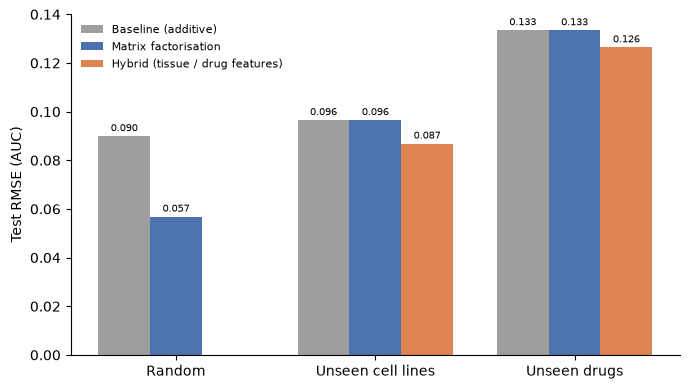

  ep    0  train mse 0.02159
  ep  100  train mse 0.00101
  ep  200  train mse 0.00100
  ep  300  train mse 0.00100


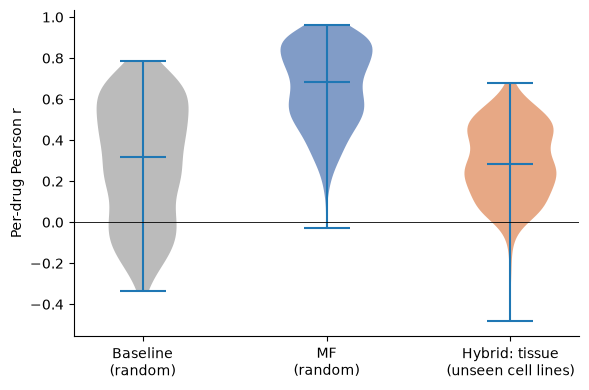

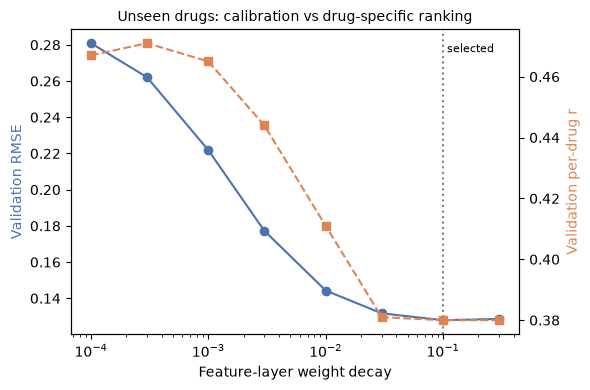

per-drug r medians: 0.319 0.683 0.284


In [27]:
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)
res = json.load(open('results.json'))
keys, labels = ['random', 'cell_blind', 'drug_blind'], ['Random', 'Unseen cell lines', 'Unseen drugs']

# --- Fig 1: RMSE by split and model ---
base_v = [res['baseline_final'][k]['rmse_mean'] for k in keys]
mf_v = [res['mf_final'][k]['rmse_mean'] for k in keys]
hyb_v = [res['hybrid_cell_final']['tissue']['rmse_mean'], res['hybrid_drug_final']['rmse_mean']]
x, w = np.arange(3), 0.26
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w, base_v, w, label='Baseline (additive)', color='#9e9e9e')
b2 = ax.bar(x, mf_v, w, label='Matrix factorisation', color='#4c72b0')
b3 = ax.bar(x[1:] + w, hyb_v, w, label='Hybrid (tissue / drug features)', color='#dd8452')
for b in (b1, b2, b3): ax.bar_label(b, fmt='%.3f', fontsize=7, padding=2)
ax.set_xticks(x, labels); ax.set_ylabel('Test RMSE (AUC)')
ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('figures/fig1_rmse.png', dpi=300); plt.show()

# --- Fig 2: per-drug r distributions ---
def r_array(pred, te):
    t = pd.DataFrame({'d': df.drug_i.values[te], 'y': df.AUC.values[te], 'p': pred})
    return np.array([g.y.corr(g.p) for _, g in t.groupby('d') if g.p.nunique() > 1 and len(g) > 2])

r_base = r_array(baseline_pred(splits['random_tr'], splits['random_te']), splits['random_te'])
m_rand, mu_rand = fit(splits['random_tr'], k=64, wd=1e-5, seed=0)
torch.save({'state_dict': m_rand.state_dict(), 'mu': mu_rand, 'k': 64, 'n_cells': n_cells, 'n_drugs': n_drugs},
           'models/mf_random_final.pt')
r_mf = per_drug_r(m_rand, mu_rand, splits['random_te'], splits['random_tr'])
ck_c = torch.load('models/hybrid_cell_final.pt', weights_only=False)
r_cell = per_drug_r(m_ct, ck_c['mu'], splits['cell_blind_te'], splits['cell_blind_tr'])

fig, ax = plt.subplots(figsize=(6, 4))
parts = ax.violinplot([r_base, r_mf, r_cell], showmedians=True)
for pc, col in zip(parts['bodies'], ['#9e9e9e', '#4c72b0', '#dd8452']): pc.set_facecolor(col); pc.set_alpha(0.7)
ax.axhline(0, color='black', lw=0.6)
ax.set_xticks([1, 2, 3], ['Baseline\n(random)', 'MF\n(random)', 'Hybrid: tissue\n(unseen cell lines)'])
ax.set_ylabel('Per-drug Pearson r'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('figures/fig2_per_drug_r.png', dpi=300); plt.show()

# --- Fig 3: unseen-drug regularisation trade-off ---
sw = {float(k): v for k, v in res['wd_feat_sweep'].items()}
xs = sorted(sw); rm = [sw[k][0] for k in xs]; rr = [sw[k][1] for k in xs]
fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(xs, rm, 'o-', color='#4c72b0'); ax1.set_xscale('log')
ax1.set_xlabel('Feature-layer weight decay'); ax1.set_ylabel('Validation RMSE', color='#4c72b0')
ax2 = ax1.twinx(); ax2.plot(xs, rr, 's--', color='#dd8452')
ax2.set_ylabel('Validation per-drug r', color='#dd8452')
ax1.axvline(0.1, color='grey', ls=':'); ax1.text(0.1, max(rm), ' selected', fontsize=8, va='top')
ax1.set_title('Unseen drugs: calibration vs drug-specific ranking', fontsize=10)
fig.tight_layout(); fig.savefig('figures/fig3_tradeoff.png', dpi=300); plt.show()

print('per-drug r medians:', np.median(r_base).round(3), np.median(r_mf).round(3), np.median(r_cell).round(3))